<a href="https://colab.research.google.com/github/Rifath-Mahmud/CVPR/blob/main/CNN_Classification_Pipeline(Cat%20and%20Dog%20Example).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [64]:
from torchvision import datasets
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
data_folder = '~/data/' # This can be any directory
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [65]:
import kagglehub
path = kagglehub.dataset_download("tongpython/cat-and-dog")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'cat-and-dog' dataset.
Path to dataset files: /kaggle/input/cat-and-dog


In [66]:
import torchvision.transforms as transforms
size = 32
train_transform = transforms.Compose([
    transforms.Resize((size, size)),        # resize to model input size
    transforms.RandomHorizontalFlip(),    # horizontal flip augmentation
    transforms.RandomRotation(15),        # rotate ±15 degrees
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()                # convert PIL → tensor [0,1]
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor(),
])

train_folder = path+'/training_set/training_set'
test_folder = path+'/test_set/test_set'

train_data = datasets.ImageFolder(train_folder,transform = train_transform)
test_data = datasets.ImageFolder(test_folder,transform = val_transform)

In [88]:
print('Dataset Summary')
print('Train Data: ', len(train_data))
print('Test Data: ', len(test_data))
print('Classess and Indices: ' , test_data.class_to_idx)

Dataset Summary
Train Data:  8005
Test Data:  2023
Classess and Indices:  {'cats': 0, 'dogs': 1}


In [67]:
batch_size = 1000
learning_rate=1e-3
epoch_number = 3

In [68]:
def get_data():
  trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
  val_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)
  return trn_dl, val_dl

In [69]:
from torch.optim import SGD, Adam
def get_model():
    model = nn.Sequential(
        #Feature Extraction
        nn.Conv2d(3, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 128, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        #Classifier
        nn.Flatten(),
        nn.Linear(128*6*6, 256),
        nn.ReLU(),
        nn.Linear(256, 10)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [70]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)


@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)   # move to device here
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [71]:
trn_dl, val_dl = get_data()
model, loss_fn, optimizer = get_model()

In [72]:
from torchsummary import summary
model, loss_fn, optimizer = get_model()
summary(model, input_size=(3,32,32));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 30, 30]           1,792
              ReLU-2           [-1, 64, 30, 30]               0
         MaxPool2d-3           [-1, 64, 15, 15]               0
            Conv2d-4          [-1, 128, 13, 13]          73,856
              ReLU-5          [-1, 128, 13, 13]               0
         MaxPool2d-6            [-1, 128, 6, 6]               0
           Flatten-7                 [-1, 4608]               0
            Linear-8                  [-1, 256]       1,179,904
              ReLU-9                  [-1, 256]               0
           Linear-10                   [-1, 10]           2,570
Total params: 1,258,122
Trainable params: 1,258,122
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 1.39
Params size (MB): 4.80
Estimat

In [73]:
from torch import optim
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer,
                                  factor=0.5, patience=0,
                                  threshold = 0.001,
                                  min_lr = 1e-5,
                                  threshold_mode = 'abs')

## Training Loop ###
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
  epoch_loss, epoch_accuracy = train_one_epoch(trn_dl,model,loss_fn,optimizer)
  train_losses.append(epoch_loss)
  train_accuracies.append(epoch_accuracy)

  v_loss, v_acc =  validation(val_dl,model,loss_fn)
  val_losses.append(v_loss)
  val_accuracies.append(v_acc)

  print(f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
        f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/3] | Train Loss: 1.0422 | Train Accuracy: 43.45% | Val Loss: 1.7446 | Val Accuracy: 49.98%
Epoch [2/3] | Train Loss: 0.9429 | Train Accuracy: 50.27% | Val Loss: 0.9178 | Val Accuracy: 49.98%
Epoch [3/3] | Train Loss: 0.8010 | Train Accuracy: 49.97% | Val Loss: 0.7421 | Val Accuracy: 50.42%


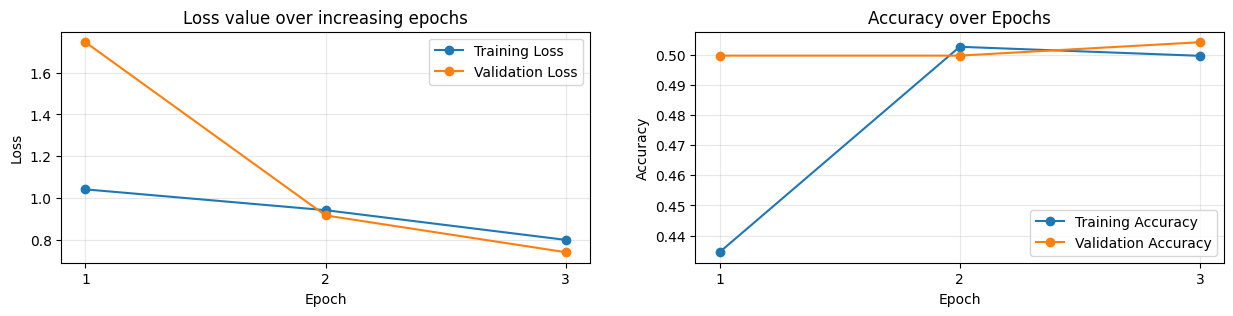

In [74]:
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3))
plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

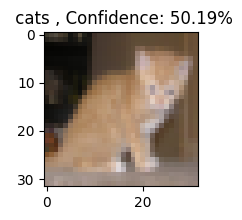

In [75]:
test_img, label = test_data[2]
img = test_img.view(-1,3,size,size).to(device)

output = model(img)
pred = torch.exp(output)/torch.sum(torch.exp(output))
confidence, index  = pred.max(-1)

plt.figure(figsize=(2,2))
plt.imshow(test_img.view(3,size,size).permute(1,2,0))
plt.title(f' {train_data.classes[index]} , Confidence: {confidence.item()*100:0.2f}%')
plt.show()